# Predicting Truck Derates from Engine Readings
**Juan Zavala** · AI for Analytics · Big NSS Express: Predicting Derates using Claude

A **full derate** is when a truck's computer cuts engine power to protect itself, leaving the truck needing a tow. This notebook works through the assignment's four parts:

1. **Part 1:** read `big_nss.csv` and compare the five measurements during a derate vs normal operation.
2. **Part 2:** fill the nulls, following the five steps the assignment lays out.
3. **Part 3:** predict whether a truck is in derate *right now*, with logistic regression and a random forest.
4. **Part 4:** predict whether a truck will derate within the next 12 hours to 21 days, and judge those predictions with ROC AUC.

Claude worked as a **pair programmer**: each part starts with a plain-English discussion, the plan is reviewed, and only then is code written and run.

| Label | Meaning |
|---|---|
| **[ME]** | A step the assignment spells out directly, which Claude wrote at my direct instruction |
| **[CLAUDE]** | Code Claude wrote after I approved its plan |
| **[REVIEW]** | What I changed or questioned in Claude's plan or code |
| **[CHECK]** | A validation step: does the code do what we think it does? |

**The data file** (`data/big_nss.csv`, 85 MB) is not committed to git. [`data/README.md`](data/README.md) says where to get it and how to confirm it's the same file.

---
# Part 1: Read the data and compare derate vs normal readings

**Prompt to Claude:**
> "I'm working in Python with pandas. Read `big_nss.csv` into a dataframe named `big_nss`. Then help me write code that compares the 5 measurement columns (`EngineOilPressure`, `EngineOilTemperature`, `DistanceLtd`, `FuelLtd`, `EngineTimeLtd`) for trucks that are in a derate vs those that aren't."

**Claude's plan:**
* Read the file, then profile it before plotting: size, time span, trucks, derate rows and nulls.
* The five columns have very different scales (psi, °F, miles, gallons, hours), so each gets its own panel.
* Compare medians and percentile ranges, not means. A few impossible values (Part 2 deals with them) would pull a mean around.

In [1]:
# [ME] Read the data into a dataframe named big_nss.
# EquipmentID is read as text; the check below shows what goes wrong otherwise.
import os, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

MEASURES = ['EngineOilPressure', 'EngineOilTemperature', 'DistanceLtd', 'FuelLtd', 'EngineTimeLtd']
OIL, LTD = MEASURES[:2], MEASURES[2:]
UNITS = {'EngineOilPressure': 'psi', 'EngineOilTemperature': '°F', 'DistanceLtd': 'miles', 'FuelLtd': 'gallons', 'EngineTimeLtd': 'hours'}

big_nss = pd.read_csv('data/big_nss.csv', index_col=0, parse_dates=['EventTimeStamp'], dtype={'EquipmentID': str})
with open('data/big_nss.csv', 'rb') as f:
    print('Same file the saved results came from:', hashlib.md5(f.read()).hexdigest() == '32170d026644c1ba9fe1be196c459f74')
print(big_nss.shape)
big_nss.head()

Same file the saved results came from: True
(1187335, 9)


,RecordID,EventTimeStamp,EquipmentID,EngineOilPressure,EngineOilTemperature,DistanceLtd,FuelLtd,EngineTimeLtd,Derate
0,1211417,2000-03-18 19:14:10,2015,25.52,190.85,274765.4,37866.421934,5673.1,False
1,1211418,2000-03-18 19:14:10,2015,25.52,190.85,274765.4,37866.421934,5673.1,False
2,1211419,2000-03-18 19:20:47,2015,NaN,NaN,NaN,NaN,NaN,False
3,1211420,2000-03-18 19:20:47,2015,NaN,NaN,NaN,NaN,NaN,False
4,1211422,2000-03-19 02:59:58,1849,NaN,NaN,NaN,NaN,NaN,False


**[REVIEW] Claude's first read used pandas' default settings, and the truck count looked wrong.** The default read reported 1,989 trucks. The check below shows why: the same truck can appear twice, once as a number and once as text. Every per-truck step in Part 2 (dropping trucks, filling within a truck) and every per-truck label in Part 4 would have been wrong, so `EquipmentID` is read as text.

In [2]:
# [CHECK] Why EquipmentID is read as text. A default read guesses each column's type in chunks of rows.
# A few IDs contain letters (such as 'R1762'), so the chunk holding them comes back as text while the other
# chunks come back as numbers, and one truck can then appear twice: as 2015 and as '2015'.
with warnings.catch_warnings():
    warnings.simplefilter('ignore')          # pandas does warn about mixed types here; that warning is the clue
    default_ids = pd.read_csv('data/big_nss.csv', index_col=0)['EquipmentID']
is_text = default_ids.map(lambda v: isinstance(v, str))
print(f'Default read: {int((~is_text).sum()):,} IDs as numbers, {int(is_text.sum()):,} as text, {default_ids.nunique():,} unique IDs')
twice = set(default_ids[is_text]) & set(default_ids[~is_text].astype(str))
print(f'Trucks that appear twice (once as a number, once as text): {len(twice):,}')
print(f'Read as text: {big_nss["EquipmentID"].nunique():,} unique IDs')
print('IDs that are not plain numbers:', sorted(i for i in big_nss['EquipmentID'].unique() if not i.isdigit()))
del default_ids, is_text

Default read: 1,056,263 IDs as numbers, 131,072 as text, 1,989 unique IDs


Trucks that appear twice (once as a number, once as text): 867
Read as text: 1,122 unique IDs
IDs that are not plain numbers: ['2185A', 'R1762', 'R1764']


In [3]:
# [CHECK] A first look: size, time span, trucks, derates and nulls
print(f'Rows: {len(big_nss):,} | trucks: {big_nss["EquipmentID"].nunique():,} | '
      f'time span: {big_nss["EventTimeStamp"].min()} to {big_nss["EventTimeStamp"].max()}')
print(f'Derate rows: {int(big_nss["Derate"].sum()):,} ({big_nss["Derate"].mean():.2%} of rows)')
print('Nulls per measurement:', {c: int(n) for c, n in big_nss[MEASURES].isna().sum().items()})
no_readings = big_nss[MEASURES].isna().all(axis=1)
print(f'Rows with all five measurements missing: {int(no_readings.sum()):,}, '
      f'including {int((no_readings & big_nss["Derate"]).sum())} of the derate rows')
print('Rows per year:', {int(y): int(n) for y, n in big_nss['EventTimeStamp'].dt.year.value_counts().sort_index().items()})
duplicates = big_nss.duplicated(subset=['EquipmentID', 'EventTimeStamp'] + MEASURES + ['Derate'])
print(f'Exact duplicate rows (same truck, time, five readings and derate flag; only RecordID differs): {int(duplicates.sum()):,}')
print(f'Oil temperatures of 3,000 °F or more: {int((big_nss["EngineOilTemperature"] >= 3000).sum())} | '
      f'lifetime counters equal to 0: {int((big_nss[LTD] == 0).values.sum()):,}')

Rows: 1,187,335 | trucks: 1,122 | time span: 2000-03-18 19:14:10 to 2026-05-16 14:44:11
Derate rows: 1,195 (0.10% of rows)


Nulls per measurement: {'EngineOilPressure': 601091, 'EngineOilTemperature': 603423, 'DistanceLtd': 601516, 'FuelLtd': 602140, 'EngineTimeLtd': 605969}
Rows with all five measurements missing: 599,700, including 631 of the derate rows
Rows per year: {2000: 219, 2002: 1, 2009: 24, 2010: 58, 2011: 244, 2015: 325779, 2016: 332383, 2017: 254851, 2018: 144510, 2019: 112075, 2020: 17188, 2026: 3}


Exact duplicate rows (same truck, time, five readings and derate flag; only RecordID differs): 129,331
Oil temperatures of 3,000 °F or more: 399 | lifetime counters equal to 0: 4,102


In [4]:
# [CLAUDE] Chart style used throughout: a light surface, quiet axes, and one accent color for derate readings
SURFACE, INK, INK2, MUTED, GRID, BASE = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
DERATE_COLOR, NORMAL_COLOR = '#eb6834', '#8a8984'
LR_COLOR, RF_COLOR, RF_HISTORY_COLOR = '#8a8984', '#2a78d6', '#104281'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': INK, 'axes.labelcolor': INK2,
                     'axes.edgecolor': BASE, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.facecolor': SURFACE,
                     'figure.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'axes.titlesize': 10.5,
                     'axes.titleweight': 'bold', 'text.parse_math': False})
def tidy(ax, grid='x'):
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(BASE)
    ax.tick_params(length=0)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
def compact(value, pos=None):
    if abs(value) < 1000:
        return f'{value:,.0f}'
    return f'{value / 1000:,.1f}'.rstrip('0').rstrip('.') + 'K'      # 7,500 -> 7.5K, 10,000 -> 10K
os.makedirs('images', exist_ok=True)
os.makedirs('results', exist_ok=True)

In [5]:
# [CLAUDE] Compare each measurement during a derate vs normal operation: percentiles of the readings, and the
# chance that a random derate reading is higher than a random normal one (0.5 means no difference)
from sklearn.metrics import roc_auc_score
PCTS = [0.10, 0.25, 0.50, 0.75, 0.90]
rows, single_auc = [], {}
for col in MEASURES:
    known = big_nss[[col, 'Derate']].dropna()
    for flag, group in [(False, 'Normal'), (True, 'Derate')]:
        values = known.loc[known['Derate'] == flag, col]
        row = {'measurement': col, 'group': group, 'readings': len(values)}
        row.update({f'p{int(p * 100)}': float(values.quantile(p)) for p in PCTS})
        rows.append(row)
    single_auc[col] = float(roc_auc_score(known['Derate'], known[col]))
compare = pd.DataFrame(rows)
separation = compare.pivot(index='measurement', columns='group', values='p50').reindex(MEASURES)[['Normal', 'Derate']]
separation.columns = ['median, normal', 'median, derate']
separation.insert(0, 'unit', [UNITS[c] for c in MEASURES])
separation['P(derate reading is higher)'] = [single_auc[c] for c in MEASURES]
for col in OIL:     # the chart title below states this, so it is checked here
    assert separation.loc[col, 'median, derate'] < separation.loc[col, 'median, normal']
separation.round(3)

,unit,"median, normal","median, derate",P(derate reading is higher)
measurement,,,,
EngineOilPressure,psi,35.960,12.759,0.139
EngineOilTemperature,°F,200.919,127.247,0.140
DistanceLtd,miles,372713.150,446059.600,0.620
FuelLtd,gallons,50583.532,63902.580,0.631
EngineTimeLtd,hours,7376.450,8946.050,0.622


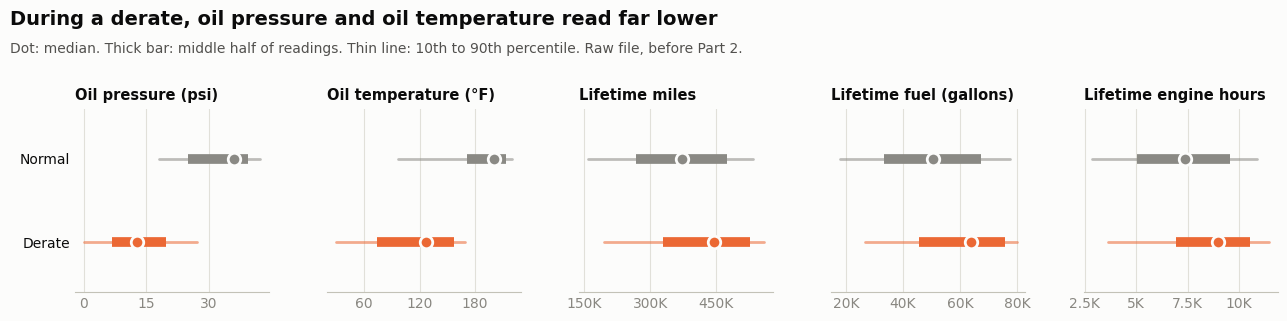

In [6]:
# [CLAUDE] Five panels, one per measurement, each on its own scale
NAMES = {'EngineOilPressure': 'Oil pressure', 'EngineOilTemperature': 'Oil temperature', 'DistanceLtd': 'Lifetime distance',
         'FuelLtd': 'Lifetime fuel', 'EngineTimeLtd': 'Lifetime engine hours'}
TITLES = {'EngineOilPressure': 'Oil pressure (psi)', 'EngineOilTemperature': 'Oil temperature (°F)', 'DistanceLtd': 'Lifetime miles',
          'FuelLtd': 'Lifetime fuel (gallons)', 'EngineTimeLtd': 'Lifetime engine hours'}
fig, axes = plt.subplots(1, 5, figsize=(13, 3.4), dpi=100)
fig.subplots_adjust(left=0.06, right=0.985, top=0.68, bottom=0.14, wspace=0.3)
for ax, col in zip(axes, MEASURES):
    tidy(ax)
    for ypos, group, color in [(1, 'Normal', NORMAL_COLOR), (0, 'Derate', DERATE_COLOR)]:
        r = compare[(compare['measurement'] == col) & (compare['group'] == group)].iloc[0]
        ax.plot([r['p10'], r['p90']], [ypos, ypos], color=color, linewidth=2, solid_capstyle='round', alpha=0.55)
        ax.plot([r['p25'], r['p75']], [ypos, ypos], color=color, linewidth=7, solid_capstyle='butt')
        ax.plot(r['p50'], ypos, 'o', color=color, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
    ax.set_ylim(-0.6, 1.6)
    ax.set_yticks([1, 0])
    ax.set_yticklabels(['Normal', 'Derate'] if ax is axes[0] else [], fontsize=10, color=INK)
    ax.set_title(TITLES[col], loc='left', color=INK)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(compact))
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4))
fig.text(0.01, 0.97, 'During a derate, oil pressure and oil temperature read far lower', fontsize=14, fontweight='bold', va='top')
fig.text(0.01, 0.875, 'Dot: median. Thick bar: middle half of readings. Thin line: 10th to 90th percentile. Raw file, before Part 2.',
         fontsize=10, color=INK2, va='top')
fig.savefig('images/derate_vs_normal.png', dpi=200)
plt.show()

In [7]:
# [CHECK] Is the difference about the moment or about the truck? Compare each truck's typical (median)
# readings for trucks that derate at least once vs trucks that never do
per_truck = big_nss.groupby('EquipmentID').agg(ever_derates=('Derate', 'max'), **{c: (c, 'median') for c in MEASURES})
truck_view = per_truck.groupby('ever_derates')[MEASURES].median().T
truck_view.columns = ['trucks that never derate', 'trucks that derate at least once']
print(f'Trucks that derate at least once: {int(per_truck["ever_derates"].sum())} of {len(per_truck):,}')
truck_view.round(1)

Trucks that derate at least once: 215 of 1,122


,trucks that never derate,trucks that derate at least once
EngineOilPressure,34.2,35.4
EngineOilTemperature,199.2,203.1
DistanceLtd,264196.7,379837.6
FuelLtd,33048.0,52132.6
EngineTimeLtd,5161.6,7466.5


### Part 1 findings

**1. During a derate, both oil readings drop sharply.**
* Median oil pressure is 12.8 psi in derate rows vs 36.0 psi in normal rows. Median oil temperature is 127 °F vs 201 °F.
* Either reading alone separates derate rows well. A random derate reading is *higher* than a random normal one only about 14% of the time (0.139 and 0.140 in the last column).

**2. Derate rows come from trucks with more miles on them.** Median lifetime distance is 446,060 miles in derate rows vs 372,713 in normal rows. Fuel and engine hours follow the same pattern (0.62 to 0.63 in the last column).

**3. The two differences are different kinds of difference.**
* Comparing trucks instead of readings: the 215 trucks that derate at least once have *typical* oil readings close to the others' (35.4 vs 34.2 psi, 203 vs 199 °F). But their median lifetime distance is 379,838 miles, vs 264,197 for trucks that never derate.
* So the oil readings describe **the moment** (what the engine is doing during a derate). The lifetime counters describe **the truck** (trucks with more miles derate more).
* That distinction comes back in Parts 3 and 4.

**4. The data needs care before modeling.** The profile found:
* 129,331 exact duplicate rows.
* 599,700 rows with no readings at all, including 631 of the 1,195 derate rows.
* Impossible values: 399 oil temperatures of 3,000 °F or more, and 4,102 lifetime counters equal to 0.
* Rows dated 2000 to 2011 and 2026, in a fleet that otherwise reports from 2015 to 2020.

Part 2 deals with each one.

---
# Part 2: Fill in the nulls

**Prompt to Claude:**
> "There are a lot of nulls, and I want to fill in as many as possible using these steps: (a) drop rows where all five measurements are null; (b) drop EquipmentIDs that have only NaNs in at least 2 of the Ltd columns; (c) where a row has at least one Ltd value, predict the others from it; (d) fill the remaining Ltd nulls in equal increments between the last and next non-null for the same EquipmentID; (e) predict missing EngineOil values from the Ltd columns, plus the other EngineOil value when only one is missing. Before writing code, tell me if anything in the data would break these steps."

**Claude's answer:** three things in the file would quietly corrupt the steps, and step (a) would cost Part 4 more than half of its derate rows:

| Problem | Why it matters | Fix (Step 0) |
|---|---|---|
| 129,331 exact duplicate rows | Double-counts readings, and copies of one reading can land on both sides of a train/test split | Remove them |
| Impossible values: oil at 3,000 °F or more, and lifetime counters of exactly 0 | A filled value interpolated from a 0 would be wrong, and a model would learn from fake readings | Treat them as missing, so the fill steps handle them |
| Clock errors: rows dated 2000 to 2011 and 2026 | Steps (d) and Part 4 depend on time order | Drop them |
| Step (a) deletes derate rows that have no readings | Those are still real derate events with real times | Save every derate time before step (a), for Part 4 |

The counts in the table come from the Part 1 profile. The code below recomputes each one as it applies the fix.

In [8]:
# [CLAUDE] Step 0, added before the assignment's steps. Each truck's readings are put in time order, then three
# problems are fixed. `steps` records rows, trucks and derate rows after every step.
work = big_nss.sort_values(['EquipmentID', 'EventTimeStamp', 'RecordID'], kind='mergesort')
steps = []
def log_step(step, df, changed):
    steps.append({'step': step, 'rows': len(df), 'trucks': int(df['EquipmentID'].nunique()),
                  'derate rows': int(df['Derate'].sum()), 'what changed': changed})
log_step('Raw file', work, '')

# 0a. Exact duplicates: same truck, timestamp, five readings and derate flag. Only RecordID differs.
duplicate = work.duplicated(subset=['EquipmentID', 'EventTimeStamp'] + MEASURES + ['Derate'])
work = work[~duplicate].copy()
log_step('0a. Remove exact duplicates', work, f'{int(duplicate.sum()):,} duplicate rows removed')

# 0b. Values that can't be real readings become NaN: oil temperatures of 3,000 °F or more and lifetime counters of 0
sentinel_temp = work['EngineOilTemperature'] >= 3000
zero_counter = work[LTD] == 0
print('Oil temperatures of 3,000 °F or more:', {float(v): int(n) for v, n in work.loc[sentinel_temp, 'EngineOilTemperature'].value_counts().sort_index().items()},
      '| derate rows among them:', int(work.loc[sentinel_temp, 'Derate'].sum()))
print('Lifetime counters equal to 0:', {c: int(n) for c, n in zero_counter.sum().items()},
      '| derate rows among them:', int(work.loc[zero_counter.any(axis=1), 'Derate'].sum()))
work.loc[sentinel_temp, 'EngineOilTemperature'] = np.nan
for col in LTD:
    work.loc[zero_counter[col], col] = np.nan
log_step('0b. Impossible values set to NaN', work, f'{int(sentinel_temp.sum())} oil temperatures and {int(zero_counter.values.sum()):,} zero counters')

# 0c. Clock errors: keep the years that hold at least 1% of the rows, the fleet's actual recording period
year = work['EventTimeStamp'].dt.year
year_share = year.value_counts(normalize=True)
fleet_years = sorted(int(y) for y in year_share.index[year_share >= 0.01])
clock_error = ~year.isin(fleet_years)
in_range = work.loc[~clock_error].groupby('EquipmentID')['DistanceLtd'].agg(['min', 'max'])
odd = work.loc[clock_error & work['DistanceLtd'].notna(), ['EquipmentID', 'DistanceLtd']].join(in_range, on='EquipmentID')
inside = odd['DistanceLtd'].between(odd['min'], odd['max'])
print(f'Clock-error rows: {int(clock_error.sum())}. Of the {len(odd)} with a mileage reading, {int(inside.sum())} have a mileage inside '
      f'the same truck\'s {fleet_years[0]}–{fleet_years[-1]} range, so the date is wrong, not the reading.')
work = work[~clock_error].copy()
log_step('0c. Drop clock-error timestamps', work, f'{int(clock_error.sum())} rows dated outside {fleet_years[0]}–{fleet_years[-1]}')
pd.DataFrame(steps)

Oil temperatures of 3,000 °F or more: {3175.446576388889: 1, 3177.258798611111: 1, 3212.488: 126, 3212.544: 48} | derate rows among them: 0
Lifetime counters equal to 0: {'DistanceLtd': 416, 'FuelLtd': 1957, 'EngineTimeLtd': 349} | derate rows among them: 0


Clock-error rows: 339. Of the 184 with a mileage reading, 170 have a mileage inside the same truck's 2015–2020 range, so the date is wrong, not the reading.


,step,rows,trucks,derate rows,what changed
0,Raw file,1187335,1122,1195,
1,0a. Remove exact duplicates,1058004,1122,1183,"129,331 duplicate rows removed"
2,0b. Impossible values set to NaN,1058004,1122,1183,"176 oil temperatures and 2,722 zero counters"
3,0c. Drop clock-error timestamps,1057665,1116,1178,339 rows dated outside 2015–2020


In [9]:
# [CHECK] The sentinel temperatures are J1939 codes, not readings. J1939 sends oil temperature as a 2-byte value in
# 0.03125 °C steps from -273 °C; the top of the valid range is 0xFAFF, and the values above it are reserved for error
# and "not available" signals.
def raw_code(fahrenheit):
    return int(round(((fahrenheit - 32) / 1.8 + 273) / 0.03125))
top_valid_f = (0xFAFF * 0.03125 - 273) * 1.8 + 32
print(f'Highest valid J1939 oil temperature: {top_valid_f:,.1f} °F')
for value in sorted(big_nss.loc[big_nss['EngineOilTemperature'] >= 3000, 'EngineOilTemperature'].unique()):
    print(f'{value:,.3f} °F decodes to raw value {raw_code(value)} = {hex(raw_code(value))}')

Highest valid J1939 oil temperature: 3,154.9 °F
3,175.447 °F decodes to raw value 64619 = 0xfc6b
3,177.259 °F decodes to raw value 64652 = 0xfc8c
3,212.488 °F decodes to raw value 65278 = 0xfefe
3,212.544 °F decodes to raw value 65279 = 0xfeff


In [10]:
# [CLAUDE] Save what Part 4 needs before any row is dropped for missing readings: every derate time, whether it starts
# an episode (the truck's previous row was not a derate), and the last time each truck was seen
episode_start = work['Derate'] & ~work.groupby('EquipmentID')['Derate'].shift(fill_value=False)
derate_events = (work.loc[work['Derate'], ['EquipmentID', 'EventTimeStamp']]
                 .assign(episode_start=episode_start[work['Derate']].to_numpy())
                 .sort_values(['EventTimeStamp', 'EquipmentID'], kind='mergesort').reset_index(drop=True))
last_seen = work.groupby('EquipmentID')['EventTimeStamp'].max()
print(f'Derate events saved: {len(derate_events):,} derate rows in {int(derate_events["episode_start"].sum())} episodes, '
      f'across {derate_events["EquipmentID"].nunique()} trucks')
episode_times = derate_events.loc[derate_events['episode_start']].sort_values(['EquipmentID', 'EventTimeStamp'], kind='mergesort')
gap_days = episode_times.groupby('EquipmentID')['EventTimeStamp'].diff().dt.total_seconds() / 86400
print(f'Derates come in clusters: for a truck\'s next episode, the median wait is {gap_days.median():.2f} days, '
      f'and {(gap_days <= 7).mean():.0%} come within 7 days of the previous one')

Derate events saved: 1,178 derate rows in 852 episodes, across 214 trucks
Derates come in clusters: for a truck's next episode, the median wait is 0.88 days, and 57% come within 7 days of the previous one


In [11]:
# [ME] 2a. Drop rows where all five measurements are null
all_missing = work[MEASURES].isna().all(axis=1)
print(f'Rows with no readings: {int(all_missing.sum()):,}, including {int(work.loc[all_missing, "Derate"].sum())} derate rows '
      f'(their times are kept in derate_events)')
work = work[~all_missing].copy()
log_step('2a. Drop rows with all 5 measurements null', work, f'{int(all_missing.sum()):,} rows removed')

# [ME] 2b. Drop trucks whose entire column is null for at least 2 of the 3 Ltd columns
column_empty = work[LTD].isna().groupby(work['EquipmentID']).all()
dropped_trucks = sorted(column_empty.index[column_empty.sum(axis=1) >= 2])
print(f'Trucks dropped: {dropped_trucks} ({int(work["EquipmentID"].isin(dropped_trucks).sum())} rows)')
work = work[~work['EquipmentID'].isin(dropped_trucks)].copy()
log_step('2b. Drop trucks missing 2+ whole Ltd columns', work, f'{len(dropped_trucks)} trucks removed')
still_empty = column_empty.drop(index=dropped_trucks).sum()
print('Trucks left with one whole Ltd column empty:', {c: int(n) for c, n in still_empty.items()})
print('Nulls left:', {c: int(n) for c, n in work[MEASURES].isna().sum().items()})

Rows with no readings: 527,038, including 623 derate rows (their times are kept in derate_events)
Trucks dropped: ['105399896', '105406598', '105406673', '105531177'] (4 rows)


Trucks left with one whole Ltd column empty: {'DistanceLtd': 0, 'FuelLtd': 0, 'EngineTimeLtd': 14}
Nulls left: {'EngineOilPressure': 950, 'EngineOilTemperature': 3167, 'DistanceLtd': 1778, 'FuelLtd': 3811, 'EngineTimeLtd': 5813}


## Step 2c: predict a missing Ltd value from a known one in the same row

**Claude's plan.** The three Ltd columns are lifetime counters, and they rise together: distance, fuel burned and engine hours. How fast each rises relative to the others depends on the truck (its fuel economy, how much it idles), so the relationship should come from that truck's own readings. Claude tested four ways of predicting a value from another Ltd column on the same row:

* **Fleet line:** one straight line for all trucks.
* **Fleet ratio:** the fleet's median ratio between the two counters.
* **Truck line:** one straight line per truck.
* **Truck neighbors:** take the truck's nearest earlier and later readings where both counters are known, and move the missing counter in proportion to the known one between them.

The test hides 5,000 known values and predicts them back.

In [12]:
# [CLAUDE] 2c helpers. A truck's rate is target per unit of source: the slope of its own straight line, or its
# median ratio when a line can't be fitted (fewer than two paired readings, or a slope that isn't positive).
def truck_lines(df, target, source):
    pairs = df[['EquipmentID', source, target]].dropna()
    by_truck = pairs.groupby('EquipmentID')
    dx = pairs[source] - by_truck[source].transform('mean')
    dy = pairs[target] - by_truck[target].transform('mean')
    sxx = (dx * dx).groupby(pairs['EquipmentID']).sum()
    lines = pd.DataFrame({'slope': (dx * dy).groupby(pairs['EquipmentID']).sum() / sxx.where(sxx > 0),
                          'mean_source': by_truck[source].mean(), 'mean_target': by_truck[target].mean(),
                          'ratio': (pairs[target] / pairs[source]).groupby(pairs['EquipmentID']).median()})
    lines['rate'] = lines['slope'].where(lines['slope'] > 0).fillna(lines['ratio'])
    return lines

def neighbor_estimate(df, target, source):
    # Estimate target from source on every row, from the same truck's nearest earlier and later rows where both are
    # known: target moves in proportion to source between those two readings. Returns (estimate, method used).
    truck = df['EquipmentID']
    both = df[source].notna() & df[target].notna()
    s_known, t_known = df[source].where(both), df[target].where(both)
    s_prev = s_known.groupby(truck).shift().groupby(truck).ffill()
    t_prev = t_known.groupby(truck).shift().groupby(truck).ffill()
    s_next = s_known.groupby(truck).shift(-1).groupby(truck).bfill()
    t_next = t_known.groupby(truck).shift(-1).groupby(truck).bfill()
    lines = truck_lines(df, target, source)
    rate, ratio = truck.map(lines['rate']), truck.map(lines['ratio'])
    s = df[source]
    rising = s_prev.notna() & s_next.notna() & (s_next > s_prev)
    flat = s_prev.notna() & s_next.notna() & ~rising
    after_last = s_prev.notna() & s_next.isna()
    before_first = s_prev.isna() & s_next.notna()
    estimate = pd.Series(np.nan, index=df.index)
    estimate.loc[rising] = (t_prev + (s - s_prev) * (t_next - t_prev) / (s_next - s_prev))[rising]
    estimate.loc[flat] = ((t_prev + t_next) / 2)[flat]
    estimate.loc[after_last] = (t_prev + (s - s_prev) * rate)[after_last]
    estimate.loc[before_first] = (t_next - (s_next - s) * rate)[before_first]
    method = pd.Series(np.select([rising, flat, after_last, before_first],
                                 ['between two readings', 'counter did not rise', 'after the last reading', 'before the first reading'],
                                 'no paired readings'), index=df.index)
    # A lifetime counter can't be 0 or below; if stepping back from the first reading goes that far, use the truck's ratio
    not_positive = estimate <= 0
    estimate.loc[not_positive] = (s * ratio)[not_positive]
    method.loc[not_positive] = 'truck ratio (line went below 0)'
    return estimate, method

In [13]:
# [CHECK] Which 2c method is most accurate? Hide 5,000 known values for each target/source pair and predict them back.
# Error is the absolute percentage error of the estimate.
from sklearn.linear_model import LinearRegression
rng = np.random.default_rng(42)
complete_ltd = work.dropna(subset=LTD)
PAIRS = [('DistanceLtd', 'FuelLtd'), ('DistanceLtd', 'EngineTimeLtd'), ('FuelLtd', 'DistanceLtd'),
         ('FuelLtd', 'EngineTimeLtd'), ('EngineTimeLtd', 'FuelLtd'), ('EngineTimeLtd', 'DistanceLtd')]
validation = []
for target, source in PAIRS:
    hide = complete_ltd.index[rng.choice(len(complete_ltd), 5000, replace=False)]
    masked = work.copy()
    masked.loc[hide, target] = np.nan
    truth, x = complete_ltd.loc[hide, target], complete_ltd.loc[hide, source]
    pairs = masked[[source, target]].dropna()
    lines = truck_lines(masked, target, source).reindex(complete_ltd.loc[hide, 'EquipmentID'])
    lines.index = hide
    estimates = {
        'fleet line': LinearRegression().fit(pairs[[source]], pairs[target]).predict(complete_ltd.loc[hide, [source]]),
        'fleet ratio': (pairs[target] / pairs[source]).median() * x,
        'truck line': lines['mean_target'] + lines['slope'] * (x - lines['mean_source']),
        'truck neighbors': neighbor_estimate(masked, target, source)[0][hide],
    }
    for name, est in estimates.items():
        error = (pd.Series(np.asarray(est), index=hide) - truth).abs() / truth * 100
        validation.append({'target': target, 'from': source, 'method': name, 'estimated': int(error.notna().sum()),
                           'median % error': float(error.median()), '99th pct % error': float(error.quantile(0.99))})
validation = pd.DataFrame(validation)
order = pd.MultiIndex.from_tuples(PAIRS, names=['target', 'from'])
ltd_check = validation.pivot_table(index=['target', 'from'], columns='method', values='median % error').reindex(order)[list(estimates)]
ltd_check_tail = validation.pivot_table(index=['target', 'from'], columns='method', values='99th pct % error').reindex(order)[list(estimates)]
validation.to_csv('results/ltd_fill_validation.csv', index=False)
print('Median % error:')
print(ltd_check.round(4).to_string())
print('\n99th percentile % error (the worst 1% of estimates):')
print(ltd_check_tail.round(2).to_string())

Median % error:
method                       fleet line  fleet ratio  truck line  truck neighbors
target        from                                                               
DistanceLtd   FuelLtd            6.6773       3.3238      0.1775           0.0004
              EngineTimeLtd      9.4721       3.2220      0.5454           0.0011
FuelLtd       DistanceLtd        4.2145       3.3130      0.1860           0.0005
              EngineTimeLtd     11.2397       4.2022      0.5084           0.0010
EngineTimeLtd FuelLtd            7.7939       4.3333      0.5638           0.0012
              DistanceLtd        3.7148       3.1057      0.6114           0.0015

99th percentile % error (the worst 1% of estimates):
method                       fleet line  fleet ratio  truck line  truck neighbors
target        from                                                               
DistanceLtd   FuelLtd            891.89        94.97       28.08             0.13
              EngineTimeLtd 

**What the test shows:**
* **Truck neighbors is far more accurate than the other three.** Its median error is 0.0004% to 0.0015%, and even its worst 1% of estimates are off by 0.26% or less.
* **One straight line per truck looks fine at the median (0.18% to 0.61%) but fails in the tail.** Its worst 1% of estimates are off by 26% to 77%. A single line has to fit a truck's whole history, so it can't follow a truck whose fuel economy or idling changes over time. The neighbor method relies only on the two closest readings.
* **Fleet-wide methods are off by 3% to 11% at the median,** because each truck has its own fuel economy and idling habits.

**[REVIEW]** Claude's first plan for 2c was the per-truck straight line. This test is why it was replaced with the neighbor method. The truck's slope is still used, but only for the few rows before a truck's first paired reading or after its last.

**Source order:**
* Each target is filled first from the column that predicted it best here: distance from fuel, fuel from distance, engine hours from fuel. The other column is tried second.
* The 14 trucks that never report engine hours have no paired readings, so the fleet's median ratio is used for them. For engine hours, the fleet ratio from distance has the lowest error (3.11%).

In [14]:
# [CLAUDE] 2c. Fill each missing Ltd value from a known Ltd value in the same row, trying the source columns in order of
# accuracy. Estimates always come from originally known values, never from values filled earlier in this step.
SOURCES = {'DistanceLtd': ['FuelLtd', 'EngineTimeLtd'], 'FuelLtd': ['DistanceLtd', 'EngineTimeLtd'], 'EngineTimeLtd': ['FuelLtd', 'DistanceLtd']}
original = work.copy()
fill_log = []
for target, sources in SOURCES.items():
    for source in sources:
        need = work[target].isna() & original[source].notna()
        estimate, method = neighbor_estimate(original, target, source)
        use = need & estimate.notna()
        work.loc[use, target] = estimate[use]
        for name, n in method[use].value_counts().items():
            fill_log.append({'target': target, 'from': source, 'method': f'truck neighbors: {name}', 'values filled': int(n)})
# A truck that never reports a column has no paired readings, so the fleet's median ratio is used instead,
# from the source with the lowest fleet-ratio error in the test above
for target in LTD:
    for source in ltd_check.loc[target, 'fleet ratio'].sort_values().index:
        need = work[target].isna() & original[source].notna()
        if need.any():
            pairs = original[[source, target]].dropna()
            work.loc[need, target] = (pairs[target] / pairs[source]).median() * original.loc[need, source]
            fill_log.append({'target': target, 'from': source, 'method': 'fleet median ratio', 'values filled': int(need.sum())})
fill_log = pd.DataFrame(fill_log)
filled_2c = int(fill_log['values filled'].sum())
log_step('2c. Predict missing Ltd values from known ones', work, f'{filled_2c:,} values filled')
fill_log.groupby(['method', 'target'], sort=False)['values filled'].sum().unstack(fill_value=0)[LTD]

target,DistanceLtd,FuelLtd,EngineTimeLtd
method,,,
truck neighbors: between two readings,986,2440,1584
truck neighbors: counter did not rise,225,801,370
truck neighbors: before the first reading,19,7,16
truck neighbors: after the last reading,18,30,34
truck neighbors: truck ratio (line went below 0),1,4,1
fleet median ratio,0,0,3279


In [15]:
# [CHECK] 2c filled only missing values, every row that had an Ltd value now has all three, and every estimate is positive
for col in LTD:
    known = original[col].notna()
    assert (work.loc[known, col] == original.loc[known, col]).all(), col
had_one = original[LTD].notna().any(axis=1)
assert work.loc[had_one, LTD].notna().all().all()
assert (work[LTD].dropna() > 0).all().all()
print(f'Values filled in 2c: {filled_2c:,} | rows still missing Ltd values (no Ltd reading at all): {int(work[LTD].isna().all(axis=1).sum())}')

Values filled in 2c: 9,815 | rows still missing Ltd values (no Ltd reading at all): 529


In [16]:
# [ME] 2d. Rows with no Ltd value at all: fill in equal increments between the truck's last and next known values.
# interpolate() treats the rows as equally spaced, which is what "equally incremented" asks for.
no_ltd = work[LTD].isna().all(axis=1)
work[LTD] = work.groupby('EquipmentID')[LTD].transform(lambda col: col.interpolate(method='linear', limit_area='inside'))
filled_2d = int((no_ltd & work[LTD].notna().all(axis=1)).sum())
edge = work[LTD].isna().any(axis=1)
print(f'Rows with no Ltd value: {int(no_ltd.sum())} | filled by interpolation: {filled_2d} | '
      f'left at a truck\'s start or end, with no next or last value to step toward: {int(edge.sum())} '
      f'(derate rows among them: {int(work.loc[edge, "Derate"].sum())})')
work = work[~edge].copy()
log_step('2d. Interpolate remaining Ltd nulls', work, f'{filled_2d * 3:,} values filled; {int(edge.sum())} edge rows dropped')
assert work[LTD].notna().all().all()

Rows with no Ltd value: 529 | filled by interpolation: 414 | left at a truck's start or end, with no next or last value to step toward: 115 (derate rows among them: 0)


**Why the edge rows are dropped:** step (d) fills a gap by stepping from the last known value to the next one. A row before a truck's first Ltd reading, or after its last, has only one side, so the rule doesn't apply. Extrapolating would be a different method than the one asked for, and these rows are a tiny share of the data (the counts are printed above).

## Step 2e: predict the missing oil readings

**Claude's plan.** Fit a separate model for each case the assignment describes, so four models in all:

* **Both oil readings missing:** predict temperature from the three Ltd columns, and pressure from the three Ltd columns.
* **Only one missing:** predict it from the three Ltd columns plus the other oil reading.

Claude tested three model types by hiding 20% of the complete rows: the overall mean (the baseline), linear regression, and gradient-boosted trees. `Derate` is never an input. It is the target in Parts 3 and 4, and using it here would leak the answer into the features.

In [17]:
# [CHECK] Which model fills the oil readings best? Train on 80% of complete rows, score MAE on the other 20%.
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
OIL_CASES = {'Temperature, both missing': ('EngineOilTemperature', LTD),
             'Pressure, both missing': ('EngineOilPressure', LTD),
             'Temperature, pressure known': ('EngineOilTemperature', LTD + ['EngineOilPressure']),
             'Pressure, temperature known': ('EngineOilPressure', LTD + ['EngineOilTemperature'])}
def boosted_trees():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, early_stopping=False, random_state=42)
complete_oil = work.dropna(subset=OIL)
fit_rows, check_rows = train_test_split(complete_oil.index, test_size=0.2, random_state=42)
oil_check = []
for case, (target, inputs) in OIL_CASES.items():
    fit, check = complete_oil.loc[fit_rows], complete_oil.loc[check_rows]
    oil_check.append({'case': case,
                      'overall mean': mean_absolute_error(check[target], np.full(len(check), fit[target].mean())),
                      'linear regression': mean_absolute_error(check[target], LinearRegression().fit(fit[inputs], fit[target]).predict(check[inputs])),
                      'boosted trees': mean_absolute_error(check[target], boosted_trees().fit(fit[inputs], fit[target]).predict(check[inputs]))})
oil_check = pd.DataFrame(oil_check).set_index('case')
oil_check['unit'] = [UNITS[t] for t, _ in OIL_CASES.values()]
oil_check.to_csv('results/oil_fill_validation.csv')
oil_check.round(2)

,overall mean,linear regression,boosted trees,unit
case,,,,
"Temperature, both missing",36.33,36.30,34.44,°F
"Pressure, both missing",9.07,9.05,8.69,psi
"Temperature, pressure known",36.33,36.30,23.31,°F
"Pressure, temperature known",9.07,9.05,8.10,psi


**What the test shows:**
* **The Ltd columns barely predict oil readings.** With both readings missing, boosted trees beat the overall mean by only 4% to 5%:
  * temperature MAE 34.44 vs 36.33 °F;
  * pressure MAE 8.69 vs 9.07 psi.

  Linear regression is no better than the mean. That makes sense, since lifetime counters describe a truck's wear, not what its engine is doing at that moment.
* **The other oil reading helps, a lot for temperature.**
  * Knowing the pressure cuts the temperature error to 23.31 °F, 36% below the mean.
  * Knowing the temperature cuts the pressure error to 8.10 psi, 11% below.
* Boosted trees had the lowest error in all four cases, so they fill all four.

In [18]:
# [CLAUDE] 2e. Fill the oil readings with boosted trees trained on every complete row. Which rows need which model is
# decided before anything is filled, so a value filled in one case is never an input to another.
both_missing = work[OIL].isna().all(axis=1)
temp_only = work['EngineOilTemperature'].isna() & work['EngineOilPressure'].notna()
pressure_only = work['EngineOilPressure'].isna() & work['EngineOilTemperature'].notna()
cases = {'Temperature, both missing': both_missing, 'Pressure, both missing': both_missing,
         'Temperature, pressure known': temp_only, 'Pressure, temperature known': pressure_only}
complete_oil = work.dropna(subset=OIL)
before_2e = work[OIL].copy()
oil_fills = {}
for case, (target, inputs) in OIL_CASES.items():
    rows_needing = cases[case]
    model = boosted_trees().fit(complete_oil[inputs], complete_oil[target])
    oil_fills[case] = pd.Series(model.predict(work.loc[rows_needing, inputs]), index=work.index[rows_needing.to_numpy()])
for case, (target, inputs) in OIL_CASES.items():
    work.loc[oil_fills[case].index, target] = oil_fills[case]
filled_2e = int(both_missing.sum() * 2 + temp_only.sum() + pressure_only.sum())
log_step('2e. Predict missing oil readings', work, f'{filled_2e:,} values filled')
pd.DataFrame({case: {'rows filled': len(v), 'lowest': float(v.min()), 'median': float(v.median()), 'highest': float(v.max())}
              for case, v in oil_fills.items()}).T.round(1)

,rows filled,lowest,median,highest
"Temperature, both missing",864.0,103.0,181.2,212.6
"Pressure, both missing",864.0,13.4,31.8,60.1
"Temperature, pressure known",2300.0,-33.0,135.1,222.9
"Pressure, temperature known",86.0,9.8,31.8,47.8


In [19]:
# [CHECK] No nulls remain, known oil readings are untouched, and filled values stay inside the range of real readings
assert work[MEASURES].notna().all().all()
for col in OIL:
    known = before_2e[col].notna()
    assert (work.loc[known, col] == before_2e.loc[known, col]).all(), col
    filled = work.loc[~known, col]
    assert filled.between(before_2e[col].min(), before_2e[col].max()).all(), col
clean = work
summary = pd.DataFrame(steps)
summary.to_csv('results/null_filling_steps.csv', index=False)
print(f'Clean data: {len(clean):,} rows, {clean["EquipmentID"].nunique():,} trucks, {int(clean["Derate"].sum())} derate rows, no nulls')
summary

Clean data: 530,508 rows, 1,092 trucks, 555 derate rows, no nulls


,step,rows,trucks,derate rows,what changed
0,Raw file,1187335,1122,1195,
1,0a. Remove exact duplicates,1058004,1122,1183,"129,331 duplicate rows removed"
2,0b. Impossible values set to NaN,1058004,1122,1183,"176 oil temperatures and 2,722 zero counters"
3,0c. Drop clock-error timestamps,1057665,1116,1178,339 rows dated outside 2015–2020
4,2a. Drop rows with all 5 measurements null,530627,1096,555,"527,038 rows removed"
5,2b. Drop trucks missing 2+ whole Ltd columns,530623,1092,555,4 trucks removed
6,2c. Predict missing Ltd values from known ones,530623,1092,555,"9,815 values filled"
7,2d. Interpolate remaining Ltd nulls,530508,1092,555,"1,242 values filled; 115 edge rows dropped"
8,2e. Predict missing oil readings,530508,1092,555,"4,114 values filled"


### Part 2 summary

| Step | What it did |
|---|---|
| 0a–0c (added) | Removed 129,331 duplicates. Turned 176 impossible oil temperatures and 2,722 zero counters into nulls. Dropped 339 rows with clock errors |
| 2a | Dropped 527,038 rows with no readings, including 623 derate rows. Their times were saved first, for Part 4 |
| 2b | Dropped 4 trucks (4 rows) missing at least two whole Ltd columns |
| 2c | Filled 9,815 Ltd values from a known Ltd value in the same row |
| 2d | Filled 414 rows (1,242 values) in equal increments. Dropped 115 rows at a truck's start or end, none of them derates |
| 2e | Filled 4,114 oil readings with boosted trees |

The clean data has 530,508 rows from 1,092 trucks, including 555 derate rows, and no nulls. Every fill left the known values untouched, which is asserted in the code.

---
# Part 3: Is the truck in derate right now?

**Prompt to Claude:**
> "Derate is my target variable. I want to predict whether it's True or False from the 3 Ltd and 2 EngineOil columns, and I want to validate the model on unseen data, so it needs a train/test split. What is a train/test split? Try both logistic regression and a random forest, and help me interpret the results, including an odds ratio and what it means. How accurate are the predictions?"

**What a train/test split is (Claude's explanation):** the model learns from one part of the data (the training set) and is graded on a part it has never seen (the test set). A model that memorized its training rows would look perfect on them, so only the test score says how it will do on new data.

**Claude's plan, and two choices that matter more than the model:**

1. **Split by truck, not by row.**
   * A truck's readings minutes apart are nearly identical. With a random row split, the test set is full of near-copies of training rows.
   * Here every truck goes entirely into training or entirely into testing (`StratifiedGroupKFold`, one of 4 folds held out), so the test means *trucks the model has never seen*.
   * A random split is run afterward, for comparison.
2. **Don't trust accuracy.**
   * About 1 reading in 1,000 is a derate, so a model that always says "no derate" is 99.9% accurate and useless.
   * The plan reports accuracy next to that baseline, then measures that handle rare events:
     * **ROC AUC:** the chance the model scores a random derate reading above a random normal one.
     * **PR AUC:** average precision. Guessing scores the derate share.
     * **Recall and precision** if we flag the top 1% or 0.5% of readings.

**The models:**

* **Logistic regression:** inputs scaled to mean 0, SD 1. It is a straight-line model of the log-odds, so its coefficients turn into odds ratios.
* **Random forest:** 100 trees, each grown on 30% of the training rows with at least 20 rows per leaf, which keeps it fast and stops single readings from being memorized.

In [20]:
# [CLAUDE] Train/test split by truck: one of 4 folds of trucks is the test set, with the derate share balanced across folds
from sklearn.model_selection import StratifiedGroupKFold
X, y, trucks = clean[MEASURES], clean['Derate'].astype(int), clean['EquipmentID']
train_idx, test_idx = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42).split(X, y, trucks))
test_trucks = set(trucks.iloc[test_idx])
assert test_trucks.isdisjoint(set(trucks.iloc[train_idx]))        # no truck is on both sides
for name, idx in [('Training', train_idx), ('Test', test_idx)]:
    print(f'{name}: {len(idx):,} readings from {trucks.iloc[idx].nunique()} trucks | derate readings: {int(y.iloc[idx].sum())} '
          f'({y.iloc[idx].mean():.3%}) from {trucks.iloc[idx][y.iloc[idx] == 1].nunique()} trucks')

Training: 391,232 readings from 820 trucks | derate readings: 404 (0.103%) from 148 trucks
Test: 139,276 readings from 272 trucks | derate readings: 151 (0.108%) from 48 trucks


In [21]:
# [CLAUDE] Fit both models on the training trucks and score them on the test trucks
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, average_precision_score, confusion_matrix
def logistic():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
def forest():
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=20, max_samples=0.3, n_jobs=-1, random_state=42)
def top_share(y_true, score, share):
    # Flag the top `share` of readings by score; return (recall, precision) of those flags
    k = max(1, int(round(share * len(score))))
    hits = y_true[np.argsort(-score, kind='stable')[:k]].sum()
    return hits / y_true.sum(), hits / k
def scorecard(y_true, score):
    y_true, score = np.asarray(y_true), np.asarray(score)
    flagged = (score >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    card = {'accuracy (threshold 0.5)': accuracy_score(y_true, flagged), 'accuracy of always saying "no derate"': 1 - y_true.mean(),
            'balanced accuracy': balanced_accuracy_score(y_true, flagged), 'ROC AUC': roc_auc_score(y_true, score),
            'PR AUC': average_precision_score(y_true, score), 'PR AUC of random guessing': y_true.mean(),
            'flagged at 0.5': int(tp + fp), 'derates caught at 0.5': int(tp)}
    for share in [0.01, 0.005]:
        recall, precision = top_share(y_true, score, share)
        card[f'recall, top {share:.1%} flagged'] = recall
        card[f'precision, top {share:.1%} flagged'] = precision
    return card
X_train, y_train, X_test, y_test = X.iloc[train_idx], y.iloc[train_idx], X.iloc[test_idx], y.iloc[test_idx]
lr_now = logistic().fit(X_train, y_train)
rf_now = forest().fit(X_train, y_train)
now_scores = {'Logistic regression': lr_now.predict_proba(X_test)[:, 1], 'Random forest': rf_now.predict_proba(X_test)[:, 1]}
current = pd.DataFrame({name: scorecard(y_test, s) for name, s in now_scores.items()})
current.to_csv('results/current_derate_metrics.csv')
current.round(4)

,Logistic regression,Random forest
accuracy (threshold 0.5),0.9989,0.9989
"accuracy of always saying ""no derate""",0.9989,0.9989
balanced accuracy,0.5000,0.5000
ROC AUC,0.9125,0.9602
PR AUC,0.0151,0.1918
PR AUC of random guessing,0.0011,0.0011
flagged at 0.5,0.0000,0.0000
derates caught at 0.5,0.0000,0.0000
"recall, top 1.0% flagged",0.1523,0.7682
"precision, top 1.0% flagged",0.0165,0.0833


In [22]:
# [CHECK] Confusion matrices at the usual 0.5 threshold: rows are the truth, columns the prediction
for name, s in now_scores.items():
    cm = pd.DataFrame(confusion_matrix(y_test, (s >= 0.5).astype(int), labels=[0, 1]), index=['truly normal', 'truly derate'], columns=['predicted normal', 'predicted derate'])
    print(name); print(cm.to_string()); print()

Logistic regression
              predicted normal  predicted derate
truly normal            139125                 0
truly derate               151                 0

Random forest
              predicted normal  predicted derate
truly normal            139125                 0
truly derate               151                 0



In [23]:
# [CHECK] How sure are the AUCs? Resample whole test trucks with replacement 1,000 times and recompute the AUC.
# The AUC is computed with weights (how many times each truck was drawn), which matches sklearn when every weight is 1.
def weighted_auc_parts(y_true, score, groups):
    order = np.argsort(score, kind='mergesort')
    s, yy = np.asarray(score)[order], np.asarray(y_true)[order].astype(float)
    starts = np.r_[0, np.flatnonzero(np.diff(s)) + 1]           # first position of each group of tied scores
    codes, uniques = pd.factorize(np.asarray(groups)[order])
    return yy, starts, codes, len(uniques)
def weighted_auc(yy, starts, w):
    pos, neg = np.add.reduceat(w * yy, starts), np.add.reduceat(w * (1 - yy), starts)
    return float((pos * (np.cumsum(neg) - neg + 0.5 * neg)).sum() / (pos.sum() * neg.sum()))
def truck_bootstrap(y_true, score, groups, n_boot=1000, seed=42):
    yy, starts, codes, n_groups = weighted_auc_parts(y_true, score, groups)
    assert np.isclose(weighted_auc(yy, starts, np.ones(len(yy))), roc_auc_score(y_true, score))
    rng = np.random.default_rng(seed)
    draws = [weighted_auc(yy, starts, np.bincount(rng.integers(0, n_groups, n_groups), minlength=n_groups)[codes].astype(float))
             for _ in range(n_boot)]
    return np.nanpercentile(draws, [2.5, 97.5])
now_ci = {name: truck_bootstrap(y_test, s, trucks.iloc[test_idx]) for name, s in now_scores.items()}
for name, (lo, hi) in now_ci.items():
    print(f'{name}: ROC AUC {roc_auc_score(y_test, now_scores[name]):.3f}, 95% range over resampled trucks {lo:.3f} to {hi:.3f}')

Logistic regression: ROC AUC 0.913, 95% range over resampled trucks 0.869 to 0.946
Random forest: ROC AUC 0.960, 95% range over resampled trucks 0.926 to 0.981


### What the scores say

**1. Accuracy is the wrong measure here.**
* Both models score 99.89% accuracy, exactly the same as always answering "no derate". At the usual 0.5 threshold, neither model flags a single reading, so 0 of the 151 test derate readings are caught.
* Balanced accuracy, which averages the hit rate within each class, is 0.50: the score of a coin flip.

**2. The models do rank derate readings well.**
* ROC AUC on trucks neither model saw in training:
  * Logistic regression: 0.913 (95% range over resampled test trucks: 0.869 to 0.946).
  * Random forest: 0.960 (0.926 to 0.981).
* PR AUC is 0.015 for logistic regression and 0.192 for the forest, against 0.0011 for random guessing.

**3. The gap shows up when we flag the riskiest readings.**
* **Top 1% of test readings flagged:**
  * The random forest catches 77% of the derate readings, and 8% of its flags are real.
  * Logistic regression catches 15%.
* **Top 0.5% flagged:** the forest still catches 72%, and 16% of its flags are real.

## Odds ratios

**Claude's plan.**

* **The fit:** refit the logistic regression without its default penalty, so the coefficients are the plain maximum-likelihood estimates. The inputs are standardized: each coefficient is per 1 standard deviation.
* **Units:** each odds ratio is also converted to a unit that's easy to picture (per 10 psi, 10 °F, 100,000 miles, 10,000 gallons, 1,000 hours).
* **Intervals:** 95% intervals use standard errors **clustered by truck**. Readings from one truck aren't independent, and treating 391,000 readings as independent would make the intervals look far more certain than they are.
* **Collinearity:** the variance inflation factor (VIF) checks first whether the three Ltd counters, which rise together, can be read one at a time.

In [24]:
# [CLAUDE] Odds ratios from an unpenalized logistic regression, with truck-clustered 95% intervals (numpy, no extra packages)
train = clean.iloc[train_idx]
mu, sd = train[MEASURES].mean(), train[MEASURES].std(ddof=0)
Z = ((train[MEASURES] - mu) / sd).to_numpy()
yt = train['Derate'].astype(int).to_numpy()
plain = LogisticRegression(penalty=None, max_iter=5000, tol=1e-10).fit(Z, yt)
A = np.column_stack([np.ones(len(Z)), Z])
beta = np.r_[plain.intercept_, plain.coef_.ravel()]
p = plain.predict_proba(Z)[:, 1]
bread = np.linalg.inv((A * (p * (1 - p))[:, None]).T @ A)
by_truck = pd.DataFrame(A * (yt - p)[:, None]).groupby(train['EquipmentID'].to_numpy()).sum().to_numpy()
G, (n, k) = len(by_truck), A.shape
clustered_cov = G / (G - 1) * (n - 1) / (n - k) * bread @ (by_truck.T @ by_truck) @ bread
se = np.sqrt(np.diag(clustered_cov))[1:]
naive_se = np.sqrt(np.diag(bread))[1:]
PER = {'EngineOilPressure': 10, 'EngineOilTemperature': 10, 'DistanceLtd': 100000, 'FuelLtd': 10000, 'EngineTimeLtd': 1000}
vif = [1 / (1 - LinearRegression().fit(np.delete(Z, j, axis=1), Z[:, j]).score(np.delete(Z, j, axis=1), Z[:, j])) for j in range(len(MEASURES))]
odds = pd.DataFrame({
    'per': [f'{PER[c]:,} {UNITS[c]}' for c in MEASURES],
    'odds ratio': np.exp(beta[1:] * np.array([PER[c] for c in MEASURES]) / sd.to_numpy()),
    '95% low': np.exp((beta[1:] - 1.96 * se) * np.array([PER[c] for c in MEASURES]) / sd.to_numpy()),
    '95% high': np.exp((beta[1:] + 1.96 * se) * np.array([PER[c] for c in MEASURES]) / sd.to_numpy()),
    'odds ratio per 1 SD': np.exp(beta[1:]), '1 SD is': [f'{s:,.1f} {UNITS[c]}' for c, s in sd.items()],
    'clustered / naive SE': se / naive_se, 'VIF': vif}, index=MEASURES)
odds.to_csv('results/odds_ratios.csv')
odds.round(3)

,per,odds ratio,95% low,95% high,odds ratio per 1 SD,1 SD is,clustered / naive SE,VIF
EngineOilPressure,10 psi,0.570,0.532,0.611,0.500,12.3 psi,1.200,1.002
EngineOilTemperature,10 °F,0.840,0.822,0.859,0.445,46.6 °F,1.355,1.001
DistanceLtd,"100,000 miles",1.137,0.857,1.510,1.198,"140,288.0 miles",1.824,4.150
FuelLtd,"10,000 gallons",1.116,0.977,1.274,1.275,"22,172.9 gallons",1.548,3.892
EngineTimeLtd,"1,000 hours",1.017,0.994,1.041,1.066,"3,731.2 hours",0.869,2.326


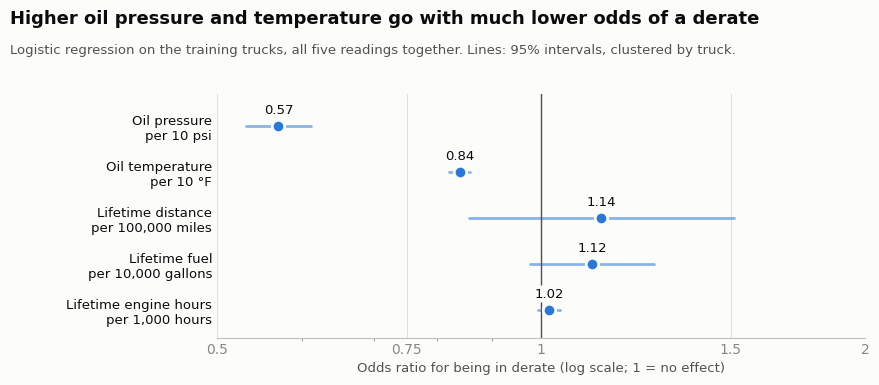

In [25]:
# [CLAUDE] The odds ratios as a chart: a dot per measurement with its 95% interval, on a log scale where 1 means no effect
fig, ax = plt.subplots(figsize=(9, 4.0), dpi=100)
fig.subplots_adjust(left=0.24, right=0.96, top=0.76, bottom=0.15)
tidy(ax)
for i, col in enumerate(MEASURES[::-1]):
    r = odds.loc[col]
    ax.plot([r['95% low'], r['95% high']], [i, i], color=RF_COLOR, linewidth=2, solid_capstyle='round', alpha=0.55)
    ax.plot(r['odds ratio'], i, 'o', color=RF_COLOR, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
    ax.annotate(f"{r['odds ratio']:.2f}", (r['odds ratio'], i), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9.5, color=INK,
                bbox=dict(boxstyle='round,pad=0.15', facecolor=SURFACE, edgecolor='none'), zorder=4)
ax.axvline(1, color=INK2, linewidth=1)
ax.set_xscale('log')
ax.set_xticks([0.5, 0.75, 1, 1.5, 2]); ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f'{v:g}'))
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_yticks(range(len(MEASURES)))
ax.set_yticklabels([f"{NAMES[c]}\nper {odds.loc[c, 'per']}" for c in MEASURES[::-1]], color=INK, fontsize=9.5)
ax.set_ylim(-0.6, len(MEASURES) - 0.3)
ax.set_xlabel('Odds ratio for being in derate (log scale; 1 = no effect)', fontsize=9.5)
fig.text(0.01, 0.97, 'Higher oil pressure and temperature go with much lower odds of a derate', fontsize=13, fontweight='bold', va='top')
fig.text(0.01, 0.885, 'Logistic regression on the training trucks, all five readings together. Lines: 95% intervals, clustered by truck.',
         fontsize=9.5, color=INK2, va='top')
fig.savefig('images/odds_ratios.png', dpi=200)
plt.show()

### What the odds ratios mean

An odds ratio says how the odds of being in derate change when one reading goes up by the stated amount, **with the other four held fixed**. Below 1 means lower odds; above 1 means higher.

* **Oil pressure: 0.57 per 10 psi (95% interval 0.53 to 0.61).** Each extra 10 psi of oil pressure goes with 43% lower odds of being in derate. Put the other way, a reading 10 psi lower has about 1.75 times the odds.
* **Oil temperature: 0.84 per 10 °F (0.82 to 0.86).** Each extra 10 °F goes with 16% lower odds.
* **Lifetime counters: no clear effect once the oil readings are in the model.** All three intervals include 1:
  * distance: 0.86 to 1.51 per 100,000 miles;
  * fuel: 0.98 to 1.27 per 10,000 gallons;
  * engine hours: 0.99 to 1.04 per 1,000 hours.

**Three cautions:**
* **Clustering matters.** The clustered standard errors are up to 1.8 times the naive ones (for distance), because readings from one truck move together. Naive intervals would have made the counters look more certain than they are.
* **The counters overlap.** They rise together (VIFs of 2.3 to 4.1), so their separate odds ratios shouldn't be over-read. The oil readings' VIFs are 1.0, so their odds ratios can be read one at a time.
* **These are associations, not causes.** Readings taken *during* a derate are partly a symptom of it. The assignment notes the measurements can be unreliable then.

In [26]:
# [CHECK] What if we had split rows at random instead of by truck?
from sklearn.model_selection import train_test_split
r_train, r_test = train_test_split(np.arange(len(clean)), test_size=0.25, stratify=y, random_state=42)
print(f'Random split: {len(set(trucks.iloc[r_train]) & set(trucks.iloc[r_test]))} trucks appear on both sides')
random_split = {}
for name, make in [('Logistic regression', logistic), ('Random forest', forest)]:
    s = make().fit(X.iloc[r_train], y.iloc[r_train]).predict_proba(X.iloc[r_test])[:, 1]
    random_split[name] = roc_auc_score(y.iloc[r_test], s)
    print(f'{name}: ROC AUC {random_split[name]:.3f} with a random row split vs {roc_auc_score(y_test, now_scores[name]):.3f} on unseen trucks')

Random split: 1033 trucks appear on both sides


Logistic regression: ROC AUC 0.923 with a random row split vs 0.913 on unseen trucks


Random forest: ROC AUC 0.984 with a random row split vs 0.960 on unseen trucks


In [27]:
# [CHECK] Which readings does the random forest rely on? Shuffle one column at a time in the test set and measure
# how much the ROC AUC drops (permutation importance)
from sklearn.inspection import permutation_importance
importance = permutation_importance(rf_now, X_test, y_test, scoring='roc_auc', n_repeats=3, random_state=42)
pd.Series(importance.importances_mean, index=MEASURES, name='ROC AUC drop when shuffled').sort_values(ascending=False).round(3)

EngineOilPressure       0.281
EngineOilTemperature    0.152
EngineTimeLtd           0.001
DistanceLtd            -0.007
FuelLtd                -0.008
Name: ROC AUC drop when shuffled, dtype: float64

### How accurate are the predictions?

**By accuracy alone, 99.89%. That number means nothing here, because a model that never predicts a derate scores the same.** On trucks the models have never seen:

* **The random forest ranks derate readings well:** ROC AUC 0.960, 95% range 0.926 to 0.981. If we flag the riskiest 1% of readings, it catches 77% of the derate readings, though only 8% of the flags are real.
* **Logistic regression ranks them less well:** ROC AUC 0.913. It catches 15% at the same alert level. Its straight-line form (in the log-odds) is less flexible than the forest's.
* **Both rely on the oil readings.** Shuffling oil pressure costs the forest 0.281 of ROC AUC, and oil temperature 0.152. Shuffling any lifetime counter costs at most 0.001.
* **A random row split would have overstated the forest:** ROC AUC 0.984 vs 0.960. Under that split, 1,033 trucks would have had readings on both sides.

The bigger limitation is what this model is for: it recognizes a derate that is already happening. Part 4 asks the useful question.